In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px

In [3]:
# Task 1: Data Import & Setup

df=pd.read_csv(r"C:\Users\pc\Downloads\Data Analytics\Python\social_media_engagement_5000.csv")

In [4]:
df.head()

,user_id,age,gender,country,post_id,post_type,post_category,likes,comments,shares,watch_time_sec,impression_count,posted_at,follower_count,is_verified,device_type,sentiment,hashtags,engagement_rate
0,25795,43.0,Female,Brazil,496713,image,fitness,7011.0,354.0,1157.0,5726,44650,17-12-2022,81734,False,mobile,negative,#foodie #travel #love,0.190862
1,10860,33.0,Male,Brazil,157326,reel,food,11750.0,2606.0,1807.0,5947,80216,02-06-2023,5963,False,mobile,negative,#fitness,0.201493
2,86820,32.0,Female,UK,109864,text,food,4862.0,344.0,955.0,6946,44858,07-05-2023,501783,False,tablet,positive,#foodie,0.137345
3,64886,51.0,Other,France,848877,text,fitness,5350.0,1083.0,1049.0,229,70455,12-02-2023,480212,False,mobile,negative,#music #foodie #fun,0.106195
4,16265,34.0,Other,UK,449706,image,fitness,12682.0,2735.0,1300.0,4798,6019,23-05-2023,383936,False,mobile,negative,#travel,2.777372


In [5]:
df.tail()

,user_id,age,gender,country,post_id,post_type,post_category,likes,comments,shares,watch_time_sec,impression_count,posted_at,follower_count,is_verified,device_type,sentiment,hashtags,engagement_rate
4995,59500,44.0,Male,Australia,441541,video,education,16210.0,2013.0,1837.0,6190,42977,25-06-2022,646147,False,mobile,positive,#travel #fun,0.466761
4996,22100,38.0,Other,UAE,677076,reel,education,16924.0,2734.0,1583.0,7764,34196,18-11-2022,584603,False,desktop,negative,#foodie #reels,0.621155
4997,67021,63.0,Female,USA,273595,text,travel,13487.0,NaN,167.0,7466,23680,06-04-2023,483550,False,desktop,positive,#lifestyle #tech,0.679688
4998,29800,13.0,Female,Germany,785644,video,fitness,16894.0,1289.0,1713.0,4991,89013,16-05-2022,183295,False,tablet,positive,#reels #love #fitness,0.223518
4999,73400,54.0,Other,Japan,712252,text,travel,14830.0,503.0,1798.0,3743,14234,04-03-2023,585760,False,desktop,neutral,#foodie #lifestyle #fashion,1.203527


In [6]:
print(df.shape)

(5000, 19)


In [7]:
print(df.columns)

Index(['user_id', 'age', 'gender', 'country', 'post_id', 'post_type',
       'post_category', 'likes', 'comments', 'shares', 'watch_time_sec',
       'impression_count', 'posted_at', 'follower_count', 'is_verified',
       'device_type', 'sentiment', 'hashtags', 'engagement_rate'],
      dtype='str')


In [8]:
print(df.dtypes)

user_id               int64
age                 float64
gender                  str
country                 str
post_id               int64
post_type               str
post_category           str
likes               float64
comments            float64
shares              float64
watch_time_sec        int64
impression_count      int64
posted_at               str
follower_count        int64
is_verified            bool
device_type             str
sentiment               str
hashtags                str
engagement_rate     float64
dtype: object


In [10]:
df['posted_at'] = pd.to_datetime(
    df['posted_at'], format='%d-%m-%Y'
)


In [11]:
likes = df['likes'].dropna().to_numpy()

In [12]:
print("Average Likes:", np.mean(likes))
print("Maximum Likes:", np.max(likes))
print("Minimum Likes:", np.min(likes))

Average Likes: 10107.043711340206
Maximum Likes: 19998.0
Minimum Likes: 10.0


In [13]:
# Task 2- Data Cleaning
print(df.isnull().sum())
print(df.isna().sum())

user_id               0
age                 150
gender              150
country               0
post_id               0
post_type             0
post_category         0
likes               150
comments            150
shares              150
watch_time_sec        0
impression_count      0
posted_at             0
follower_count        0
is_verified           0
device_type           0
sentiment           150
hashtags              0
engagement_rate       0
dtype: int64
user_id               0
age                 150
gender              150
country               0
post_id               0
post_type             0
post_category         0
likes               150
comments            150
shares              150
watch_time_sec        0
impression_count      0
posted_at             0
follower_count        0
is_verified           0
device_type           0
sentiment           150
hashtags              0
engagement_rate       0
dtype: int64


In [14]:
df['age'] = df['age'].fillna(df['age'].median())
df['likes'] = df['likes'].fillna(df['likes'].median())
df['comments'] = df['comments'].fillna(df['comments'].median())
df['shares'] = df['shares'].fillna(df['shares'].median())


In [15]:
df['gender'] = df['gender'].fillna(df['gender'].mode()[0])
df['sentiment'] = df['sentiment'].fillna(df['sentiment'].mode()[0])


In [16]:
print(df.isnull().sum())

user_id             0
age                 0
gender              0
country             0
post_id             0
post_type           0
post_category       0
likes               0
comments            0
shares              0
watch_time_sec      0
impression_count    0
posted_at           0
follower_count      0
is_verified         0
device_type         0
sentiment           0
hashtags            0
engagement_rate     0
dtype: int64


In [17]:
print("Duplicate rows:", df.duplicated().sum())

df = df.drop_duplicates()

print("Shape after removing duplicates:", df.shape)

Duplicate rows: 0
Shape after removing duplicates: (5000, 19)


In [18]:
columns = ['gender', 'country', 'post_type',
           'post_category', 'device_type', 'sentiment']

for col in columns:
    df[col] = df[col].astype('string').str.strip().str.lower()

# Convert date
df['posted_at'] = pd.to_datetime(
    df['posted_at'], format='%d-%m-%Y'
)

print(df.dtypes)

user_id                      int64
age                        float64
gender                      string
country                     string
post_id                      int64
post_type                   string
post_category               string
likes                      float64
comments                   float64
shares                     float64
watch_time_sec               int64
impression_count             int64
posted_at           datetime64[us]
follower_count               int64
is_verified                   bool
device_type                 string
sentiment                   string
hashtags                       str
engagement_rate            float64
dtype: object


In [19]:
import re

df['hashtags'] = df['hashtags'].fillna('').astype(str).str.lower()

df['hashtag_count'] = df['hashtags'].apply(
    lambda x: len(re.findall(r'(?<!\w)#\w+', x))
)

print(df[['hashtags', 'hashtag_count']].head())

                hashtags  hashtag_count
0  #foodie #travel #love              3
1               #fitness              1
2                #foodie              1
3    #music #foodie #fun              3
4                #travel              1


In [20]:
# Task 3- Data Exploration using Pandas
print(df.head())
print(df.tail())
print(df.shape)
print(df.columns)

   user_id   age  gender country  post_id post_type post_category    likes  \
0    25795  43.0  female  brazil   496713     image       fitness   7011.0   
1    10860  33.0    male  brazil   157326      reel          food  11750.0   
2    86820  32.0  female      uk   109864      text          food   4862.0   
3    64886  51.0   other  france   848877      text       fitness   5350.0   
4    16265  34.0   other      uk   449706     image       fitness  12682.0   

   comments  shares  watch_time_sec  impression_count  posted_at  \
0     354.0  1157.0            5726             44650 2022-12-17   
1    2606.0  1807.0            5947             80216 2023-06-02   
2     344.0   955.0            6946             44858 2023-05-07   
3    1083.0  1049.0             229             70455 2023-02-12   
4    2735.0  1300.0            4798              6019 2023-05-23   

   follower_count  is_verified device_type sentiment               hashtags  \
0           81734        False      mobile 

In [21]:
df.info()

print(df.dtypes)

<class 'pandas.DataFrame'>
RangeIndex: 5000 entries, 0 to 4999
Data columns (total 20 columns):
 #   Column            Non-Null Count  Dtype         
---  ------            --------------  -----         
 0   user_id           5000 non-null   int64         
 1   age               5000 non-null   float64       
 2   gender            5000 non-null   string        
 3   country           5000 non-null   string        
 4   post_id           5000 non-null   int64         
 5   post_type         5000 non-null   string        
 6   post_category     5000 non-null   string        
 7   likes             5000 non-null   float64       
 8   comments          5000 non-null   float64       
 9   shares            5000 non-null   float64       
 10  watch_time_sec    5000 non-null   int64         
 11  impression_count  5000 non-null   int64         
 12  posted_at         5000 non-null   datetime64[us]
 13  follower_count    5000 non-null   int64         
 14  is_verified       5000 non-null   b

In [22]:
df.describe()

,user_id,age,post_id,likes,comments,shares,watch_time_sec,impression_count,posted_at,follower_count,engagement_rate,hashtag_count
count,5000.000000,5000.000000,5000.000000,5000.000000,5000.000000,5000.0000,5000.000000,5000.000000,5000,5000.000000,5000.000000,5000.000000
mean,54561.890800,38.440400,548042.909000,10106.997400,1502.039800,1002.9106,4014.503200,50013.732800,2022-12-28 13:21:30.240000,393698.224800,0.964356,1.998600
min,10055.000000,13.000000,100068.000000,10.000000,0.000000,0.0000,0.000000,105.000000,2022-01-01 00:00:00,87.000000,0.006363,1.000000
25%,32309.500000,26.000000,322543.500000,5235.000000,792.000000,511.0000,2017.750000,24988.250000,2022-07-03 18:00:00,194480.000000,0.145781,1.000000
50%,54374.500000,38.000000,548077.500000,10105.500000,1497.000000,1012.0000,4034.500000,49934.500000,2022-12-27 00:00:00,388982.000000,0.253896,2.000000
75%,77180.500000,51.000000,771574.500000,14959.000000,2235.250000,1483.0000,6020.250000,74662.250000,2023-06-28 00:00:00,589744.250000,0.504794,3.000000
max,99963.000000,64.000000,999455.000000,19998.000000,2999.000000,1999.0000,7998.000000,99995.000000,2023-12-31 00:00:00,799533.000000,191.504348,3.000000
std,26090.370121,14.687151,260646.957267,5702.293017,856.393312,570.8552,2308.096459,28844.939104,NaN,230927.884535,5.318029,0.812853


In [23]:
print(df['gender'].value_counts())
print(df['country'].value_counts())
print(df['post_type'].value_counts())
print(df['post_category'].value_counts())
print(df['sentiment'].value_counts())

gender
male      1849
other     1581
female    1570
Name: count, dtype: int64[pyarrow]
country
india        535
canada       513
brazil       504
uae          503
usa          501
france       496
uk           493
australia    493
germany      490
japan        472
Name: count, dtype: int64[pyarrow]
post_type
reel     1283
image    1247
text     1245
video    1225
Name: count, dtype: int64[pyarrow]
post_category
fitness      675
tech         665
music        635
education    631
lifestyle    607
travel       600
fashion      594
food         593
Name: count, dtype: int64[pyarrow]
sentiment
positive    2513
neutral     1527
negative     960
Name: count, dtype: int64[pyarrow]


In [24]:
print(df['gender'].unique())
print(df['gender'].nunique())

<ArrowStringArray>
['female', 'male', 'other']
Length: 3, dtype: string
3


In [25]:
correlation = df.select_dtypes(include=np.number).corr()

print(correlation)

                   user_id       age   post_id     likes  comments    shares  \
user_id           1.000000 -0.006688  0.020051  0.025811 -0.033395  0.013763   
age              -0.006688  1.000000 -0.013153 -0.036322 -0.007284  0.013871   
post_id           0.020051 -0.013153  1.000000  0.014526 -0.010540  0.001846   
likes             0.025811 -0.036322  0.014526  1.000000 -0.018421  0.004712   
comments         -0.033395 -0.007284 -0.010540 -0.018421  1.000000  0.006142   
shares            0.013763  0.013871  0.001846  0.004712  0.006142  1.000000   
watch_time_sec   -0.016847  0.005542  0.018374  0.008710 -0.016351  0.014658   
impression_count  0.015326  0.013322 -0.007709  0.007952 -0.009395 -0.005204   
follower_count    0.010124 -0.024894 -0.002844 -0.022982 -0.011733 -0.010783   
engagement_rate  -0.004282  0.008039  0.010139  0.093520  0.000051  0.021724   
hashtag_count    -0.013692  0.007173  0.007344 -0.002190 -0.015230  0.013379   

                  watch_time_sec  impre

In [26]:
print(df.groupby('post_type')['likes'].mean())

post_type
image    10104.865277
reel     10037.802416
text     10100.148193
video    10188.600000
Name: likes, dtype: float64


In [27]:
print(df.groupby('country')['impression_count'].mean())

country
australia    48346.383367
brazil       49193.174603
canada       48703.150097
france       51727.673387
germany      48605.406122
india        52462.386916
japan        49616.135593
uae          48928.413519
uk           51119.393509
usa          51263.872255
Name: impression_count, dtype: float64


In [28]:
# Task 4- Data Wrangling
df['engagement_score'] = (
    df['likes'] + df['comments'] + df['shares']
)


In [29]:
df['hashtag_count'] = df['hashtags'].apply(
    lambda x: len(re.findall(r'(?<!\w)#\w+', str(x)))
)


In [30]:
df['log_likes'] = np.log1p(df['likes'])
df['log_comments'] = np.log1p(df['comments'])
df['log_shares'] = np.log1p(df['shares'])

print(df.head())

   user_id   age  gender country  post_id post_type post_category    likes  \
0    25795  43.0  female  brazil   496713     image       fitness   7011.0   
1    10860  33.0    male  brazil   157326      reel          food  11750.0   
2    86820  32.0  female      uk   109864      text          food   4862.0   
3    64886  51.0   other  france   848877      text       fitness   5350.0   
4    16265  34.0   other      uk   449706     image       fitness  12682.0   

   comments  shares  ...  is_verified  device_type sentiment  \
0     354.0  1157.0  ...        False       mobile  negative   
1    2606.0  1807.0  ...        False       mobile  negative   
2     344.0   955.0  ...        False       tablet  positive   
3    1083.0  1049.0  ...        False       mobile  negative   
4    2735.0  1300.0  ...        False       mobile  negative   

                hashtags  engagement_rate hashtag_count engagement_score  \
0  #foodie #travel #love         0.190862             3           8522

In [31]:
df.groupby('post_type')['engagement_score'].mean()


post_type
image    12649.390537
reel     12524.031567
text     12613.243775
video    12664.594286
Name: engagement_score, dtype: float64

In [32]:
df.groupby('country')['engagement_rate'].mean()


country
australia    1.324339
brazil       1.540704
canada       0.916659
france       1.146402
germany      0.759000
india        0.655005
japan        0.769623
uae          1.112352
uk           0.850966
usa          0.576580
Name: engagement_rate, dtype: float64

In [33]:
df.groupby('sentiment')['engagement_rate'].mean()

sentiment
negative    1.038486
neutral     0.991170
positive    0.919744
Name: engagement_rate, dtype: float64

In [34]:
df1 = df.iloc[:2500]
df2 = df.iloc[2500:]


In [36]:

combined_df = pd.concat([df1, df2], ignore_index=True)
print(combined_df.shape)

(5000, 24)


In [37]:
# Task 5- Statistical Analysis
columns = [
    'likes',
    'comments',
    'shares',
    'watch_time_sec',
    'engagement_rate',
    'follower_count'
]


In [38]:
for col in columns:

    print("\nStatistics for", col)

    print("Mean:", df[col].mean())

    print("Median:", df[col].median())

    print("Mode:", df[col].mode()[0])

    print("Standard Deviation:", df[col].std())

    print("Variance:", df[col].var())

    print("25th Percentile:", df[col].quantile(0.25))

    print("50th Percentile:", df[col].quantile(0.50))

    print("75th Percentile:", df[col].quantile(0.75))

    print("Skewness:", df[col].skew())

    print("Kurtosis:", df[col].kurtosis())


Statistics for likes
Mean: 10106.9974
Median: 10105.5
Mode: 10105.5
Standard Deviation: 5702.293017183877
Variance: 32516145.65382401
25th Percentile: 5235.0
50th Percentile: 10105.5
75th Percentile: 14959.0
Skewness: -0.006893616532184278
Kurtosis: -1.1499923609078424

Statistics for comments
Mean: 1502.0398
Median: 1497.0
Mode: 1497.0
Standard Deviation: 856.3933120458984
Variance: 733409.5049169434
25th Percentile: 792.0
50th Percentile: 1497.0
75th Percentile: 2235.25
Skewness: 0.0038017289479831415
Kurtosis: -1.1443748352968992

Statistics for shares
Mean: 1002.9106
Median: 1012.0
Mode: 1012.0
Standard Deviation: 570.8551999758852
Variance: 325875.65933950787
25th Percentile: 511.0
50th Percentile: 1012.0
75th Percentile: 1483.0
Skewness: -0.014653583910311461
Kurtosis: -1.1468565626589917

Statistics for watch_time_sec
Mean: 4014.5032
Median: 4034.5
Mode: 916
Standard Deviation: 2308.0964590420845
Variance: 5327309.264242608
25th Percentile: 2017.75
50th Percentile: 4034.5
75th 

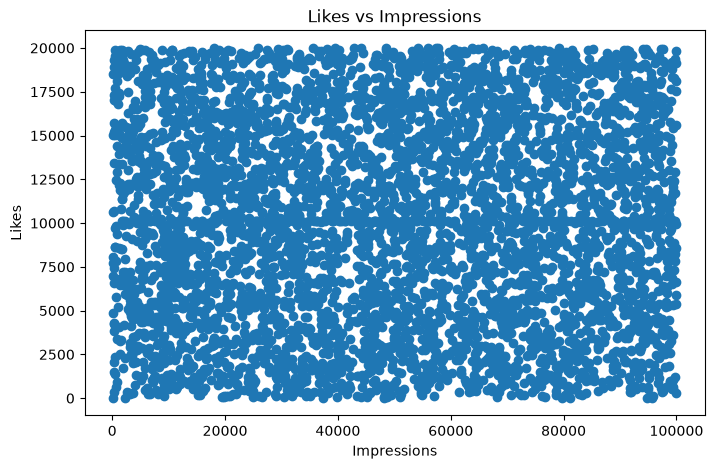

In [39]:
# Task 6- Data Visualization
plt.figure(figsize=(8,5))

plt.scatter(df['impression_count'], df['likes'])

plt.xlabel('Impressions')
plt.ylabel('Likes')

plt.title('Likes vs Impressions')

plt.show()

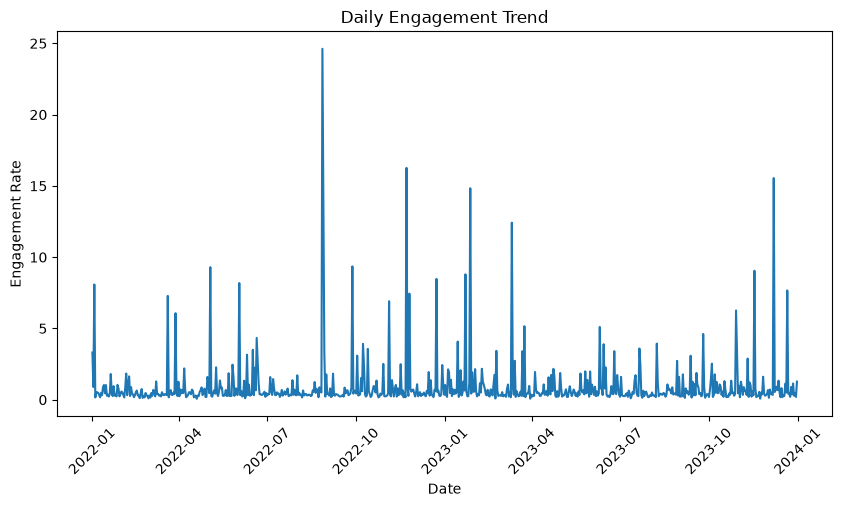

In [40]:
daily = df.groupby('posted_at')['engagement_rate'].mean()

plt.figure(figsize=(10,5))

plt.plot(daily.index, daily.values)

plt.xlabel('Date')
plt.ylabel('Engagement Rate')

plt.title('Daily Engagement Trend')

plt.xticks(rotation=45)

plt.show()

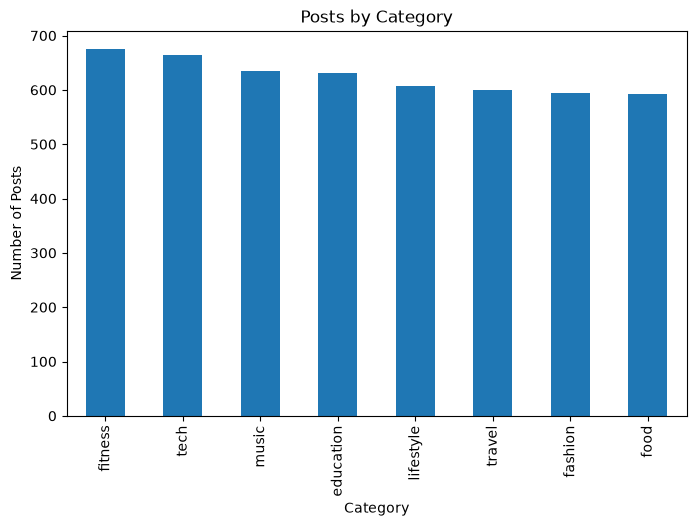

In [41]:
df['post_category'].value_counts().plot(
    kind='bar', figsize=(8,5)
)

plt.title('Posts by Category')
plt.xlabel('Category')
plt.ylabel('Number of Posts')

plt.show()

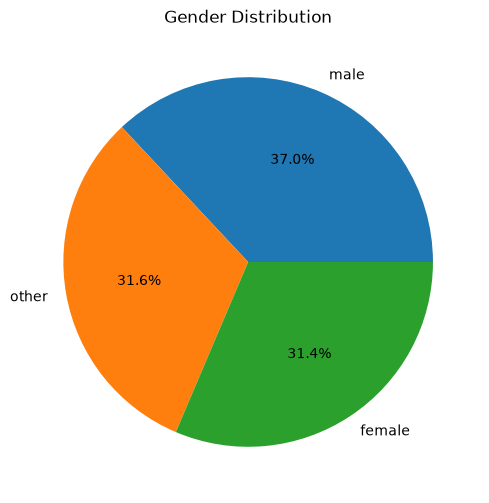

In [42]:
df['gender'].value_counts().plot(
    kind='pie', autopct='%1.1f%%', figsize=(6,6)
)

plt.title('Gender Distribution')

plt.ylabel('')

plt.show()

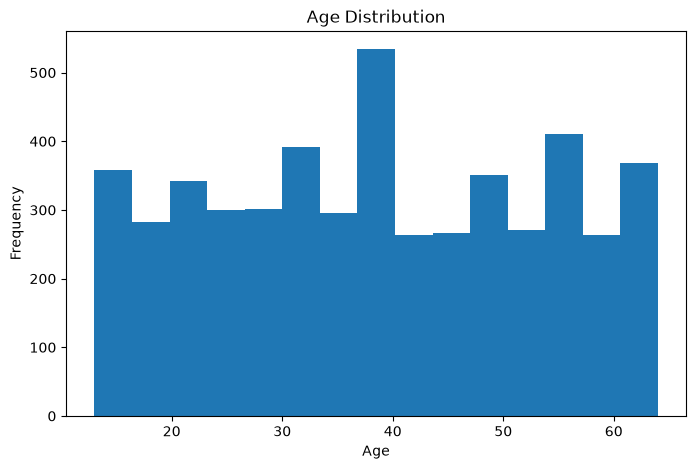

In [43]:
plt.figure(figsize=(8,5))

plt.hist(df['age'], bins=15)

plt.xlabel('Age')
plt.ylabel('Frequency')

plt.title('Age Distribution')

plt.show()

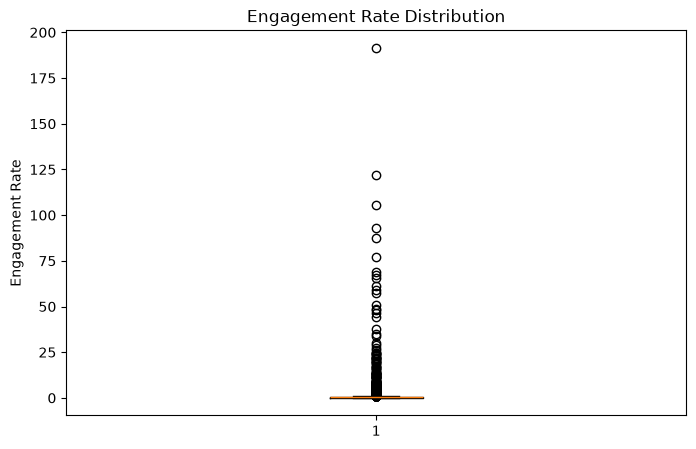

In [44]:
plt.figure(figsize=(8,5))

plt.boxplot(df['engagement_rate'])

plt.title('Engagement Rate Distribution')

plt.ylabel('Engagement Rate')

plt.show()

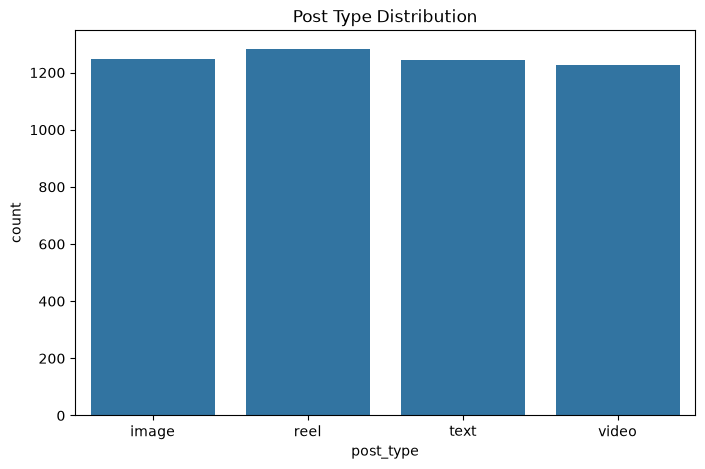

In [45]:
plt.figure(figsize=(8,5))

sns.countplot(data=df, x='post_type')

plt.title('Post Type Distribution')

plt.show()

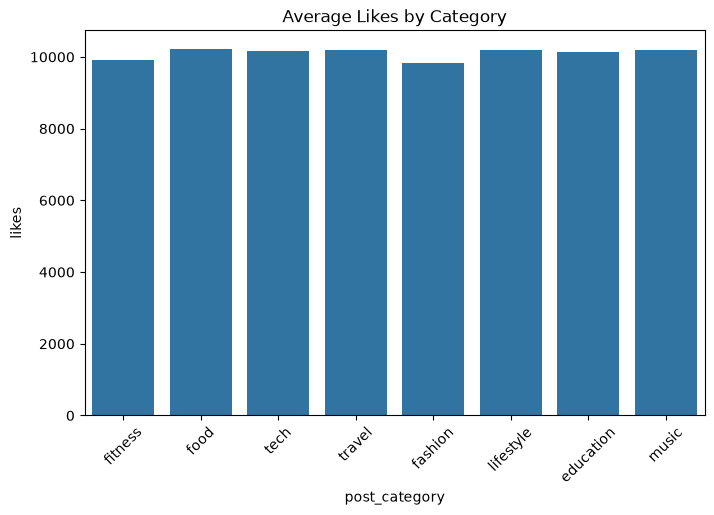

In [46]:
plt.figure(figsize=(8,5))

sns.barplot(
    data=df,
    x='post_category',
    y='likes',
    errorbar=None
)

plt.title('Average Likes by Category')

plt.xticks(rotation=45)

plt.show()

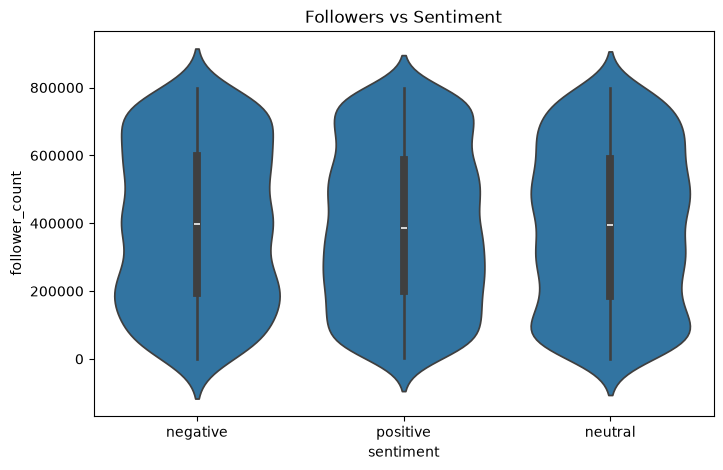

In [47]:
plt.figure(figsize=(8,5))

sns.violinplot(
    data=df,
    x='sentiment',
    y='follower_count'
)

plt.title('Followers vs Sentiment')

plt.show()

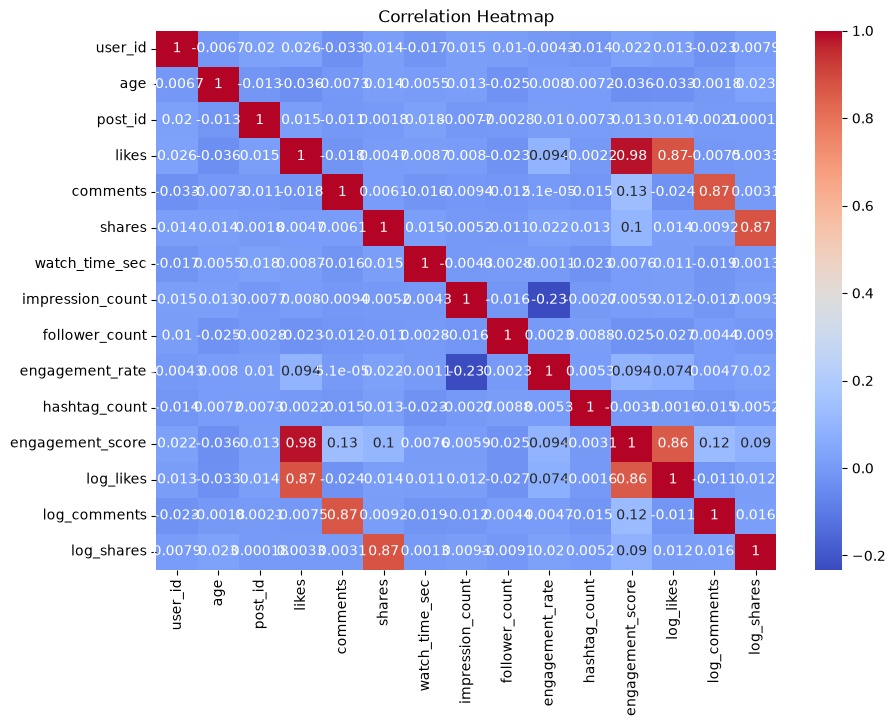

In [48]:
plt.figure(figsize=(10,7))

sns.heatmap(
    df.select_dtypes(include=np.number).corr(),
    annot=True,
    cmap='coolwarm'
)

plt.title('Correlation Heatmap')

plt.show()

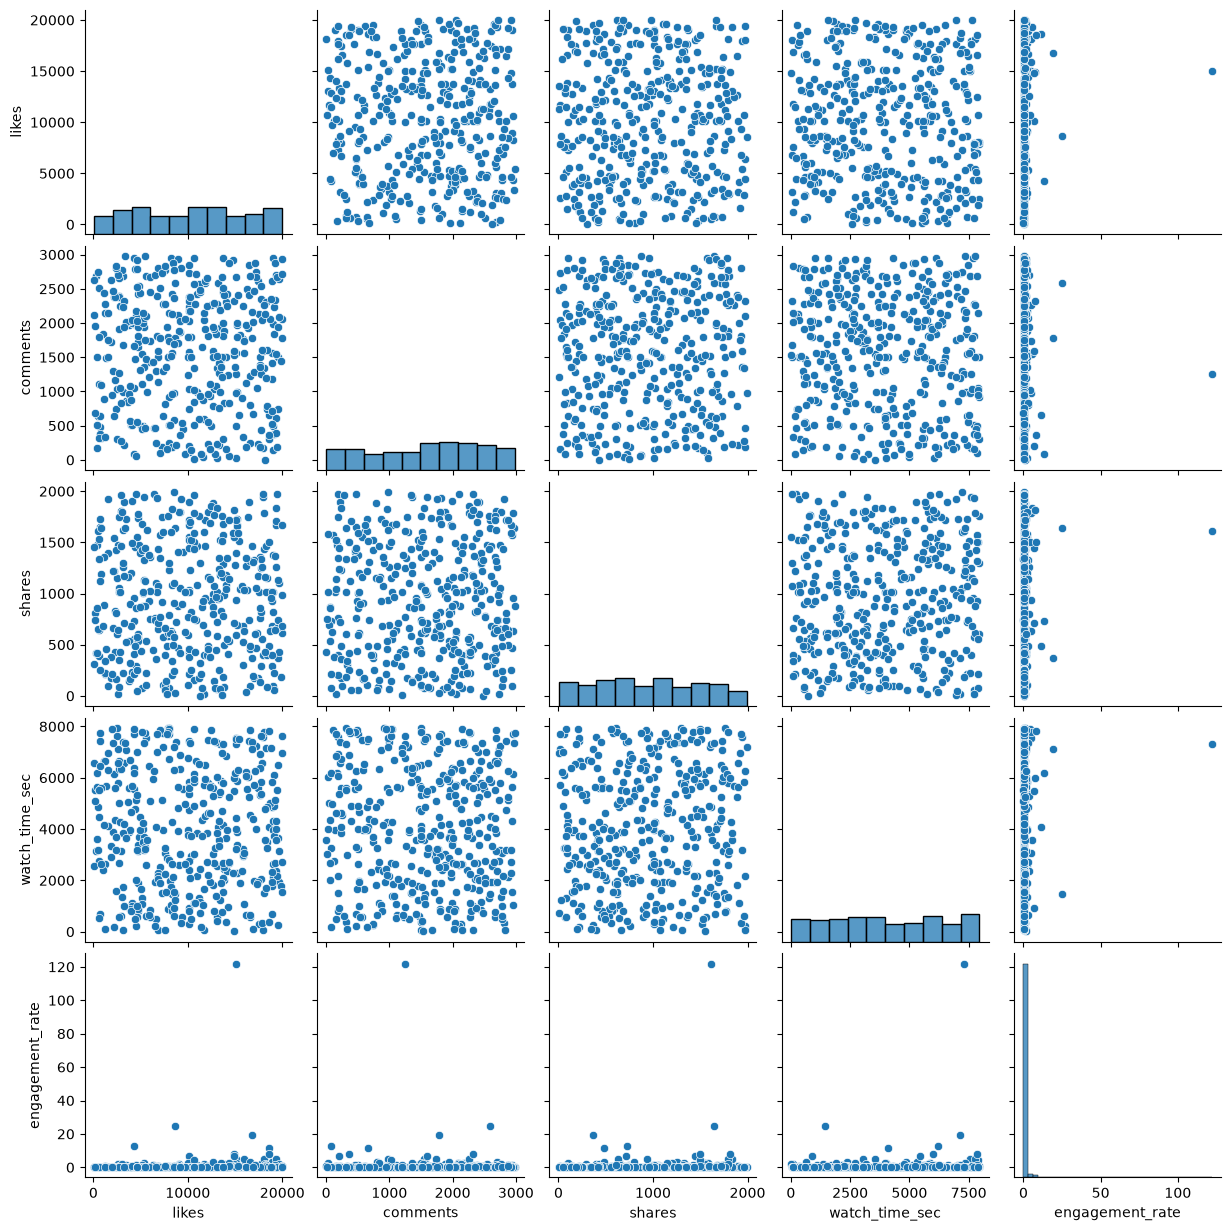

In [50]:
sns.pairplot(
    df[['likes', 'comments', 'shares',
        'watch_time_sec', 'engagement_rate']].sample(
            n=min(400, len(df)),
            random_state=42
        )
)

plt.show()

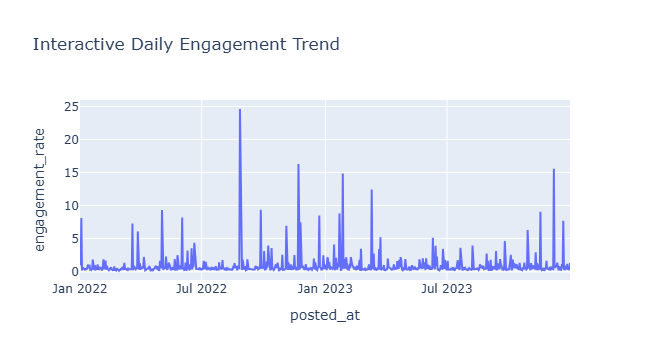

In [51]:
import plotly.express as px

fig = px.line(
    df.groupby('posted_at', as_index=False)['engagement_rate'].mean(),
    x='posted_at',
    y='engagement_rate',
    title='Interactive Daily Engagement Trend'
)

fig.show()

# Executive Summary 

This project analyzes 5,000 social media records using Python, Pandas, NumPy, Matplotlib and Seaborn. The dataset includes user details, post types, likes, comments, shares, impressions, watch time and engagement rates.

Data cleaning was performed by handling missing values, removing duplicates, correcting data types and creating new features. Exploratory data analysis and visualizations were used to identify engagement patterns.

The results show that video posts, food content and users aged 45–54 have comparatively higher engagement. Brazil has the highest average engagement rate, while mobile users have the highest watch time.

# Analytical Findings

1. Content Performance: Video posts and food category have the highest average engagement rates.

2. Country Performance: Brazil has the highest average engagement rate.

3. Age Analysis: Users aged 45–54 show the highest engagement.

4. Verified Accounts: Verified accounts have slightly higher engagement than non-verified accounts.

5. Device Impact: Mobile users have the highest average watch time.

6. Sentiment Analysis: Negative-sentiment posts have the highest average engagement rate.

7. Best Posting Time: Cannot be identified because the dataset contains dates but not posting hours.

# Conclusion

The analysis shows that content type, category, audience age, country and device type influence social media engagement patterns. These insights can help improve content strategies and audience engagement.